# Project Assignment 02: Data Exploration and Genre Analysis

**Team Fantastic Four** · CS 122, Fall 2026
Isaac Lin, Zhanxiang He, Justin Tan, Ryan Cartwright

**Project:** Netflix Genre Analyzer
**Dataset:** [Netflix Movies and TV Shows](https://www.kaggle.com/datasets/shivamb/netflix-shows) (Kaggle, CC0)

This notebook covers the first stage of our project:

1. Loading the dataset
2. Checking data quality
3. Cleaning the data (including standardizing genre labels)
4. Exploring the catalog with visualizations
5. Analyzing which genres appear together most often
6. A first prototype of the genre-based recommender

The reusable functions live in `src/genre_utils.py`, so the final program can use the same code.

## 1. Setup and loading the data

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Let the notebook import our own module from src/
sys.path.append(str(Path.cwd().parent / "src"))
from genre_utils import (
    load_netflix_data, clean_netflix_data, count_genres, count_genre_pairs,
    partner_genres, co_occurrence_matrix, recommend_titles,
)

# Consistent chart style for the whole notebook
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "x",
    "grid.color": "#e5e5e5",
    "axes.axisbelow": True,
    "font.size": 10,
})
MOVIE_COLOR = "#2a78d6"   # blue
TV_COLOR = "#eb6834"      # orange
pd.set_option("display.max_columns", None)

In [3]:
raw = load_netflix_data(Path.cwd().parent / "data" / "netflix_titles.csv")
print(raw.shape)
raw.head()

(8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


## 2. Data quality check

Before analyzing anything, we check column types and missing values.

In [4]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [5]:
missing = raw.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
pd.DataFrame({"missing": missing, "percent": (missing / len(raw) * 100).round(1)})

,missing,percent
director,2634,29.9
country,831,9.4
cast,825,9.4
date_added,10,0.1
rating,4,0.0
duration,3,0.0


**Findings:**

- `director` is missing for about 30% of titles, and `cast` and `country` for about 9%. These are not needed for genre analysis, so we fill them with `"Unknown"` instead of dropping rows.
- `listed_in` (genres) has **no missing values**, which is good because it is the core of our project.
- While checking the `rating` column, we found a data-entry error: three titles have their runtime (e.g. `"74 min"`) typed into `rating`, and their `duration` is empty.

In [7]:
raw[raw["rating"].str.contains("min", na=False)][["title", "type", "rating", "duration"]]

,title,type,rating,duration
5541,Louis C.K. 2017,Movie,74 min,NaN
5794,Louis C.K.: Hilarious,Movie,84 min,NaN
5813,Louis C.K.: Live at the Comedy Store,Movie,66 min,NaN


## 3. Data cleaning

`clean_netflix_data()` in `src/genre_utils.py` does the following:

- Moves the three misplaced runtimes from `rating` back to `duration`
- Fills missing `director`, `cast`, `country`, and `rating` with `"Unknown"`
- Converts `date_added` text (e.g. `"September 25, 2021"`) into real dates and adds a `year_added` column
- Splits `duration` into a number and a unit (minutes for movies, seasons for TV shows)
- Splits the `listed_in` text into a Python list of genres
- **Normalizes genre labels** (explained below)

### Why genre labels need normalizing

Netflix uses different labels for the same genre depending on whether a title is a movie or a TV show:

| Movie label | TV show label | Our base genre |
|---|---|---|
| Dramas | TV Dramas | Drama |
| Comedies | TV Comedies | Comedy |
| Romantic Movies | Romantic TV Shows | Romance |
| Documentaries | Docuseries | Documentary |
| Children & Family Movies | Kids' TV | Kids & Family |

Without fixing this, "romance + comedy" would be split across four different label pairs, and movies and TV shows could not be compared. We map all **42 raw labels** to **26 base genres** using a dictionary (`GENRE_MAP`). The generic labels "Movies" and "TV Shows" carry no genre information, so they are dropped.

In [8]:
df = clean_netflix_data(raw)

# Before vs. after for a few titles
df[["title", "type", "listed_in", "genres"]].head(8)

,title,type,listed_in,genres
0,Dick Johnson Is Dead,Movie,Documentaries,[Documentary]
1,Blood & Water,TV Show,"International TV Shows, TV Dramas, TV Mysteries","[International, Drama, Mystery]"
2,Ganglands,TV Show,"Crime TV Shows, International TV Shows, TV Act...","[Crime, International, Action & Adventure]"
3,Jailbirds New Orleans,TV Show,"Docuseries, Reality TV","[Documentary, Reality]"
4,Kota Factory,TV Show,"International TV Shows, Romantic TV Shows, TV ...","[International, Romance, Comedy]"
5,Midnight Mass,TV Show,"TV Dramas, TV Horror, TV Mysteries","[Drama, Horror, Mystery]"
6,My Little Pony: A New Generation,Movie,Children & Family Movies,[Kids & Family]
7,Sankofa,Movie,"Dramas, Independent Movies, International Movies","[Drama, Independent, International]"


In [10]:
raw_labels = count_genres(df["genres_raw"])
base_labels = count_genres(df["genres"])
print(f"Raw genre labels:  {len(raw_labels)}")
print(f"Base genres:       {len(base_labels)}")
print(f"Misplaced ratings fixed: {raw['rating'].str.contains('min', na=False).sum()}")
print(f"Titles with no usable genre (only 'Movies'/'TV Shows'): {(df['num_genres'] == 0).sum()}")

Raw genre labels:  42
Base genres:       26
Misplaced ratings fixed: 3
Titles with no usable genre (only 'Movies'/'TV Shows'): 73


## 4. Exploring the catalog

### 4.1 Movies vs. TV shows

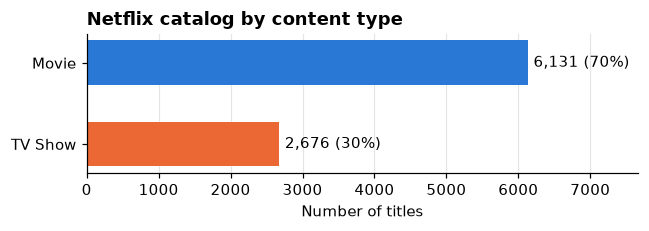

In [11]:
type_counts = df["type"].value_counts()

fig, ax = plt.subplots(figsize=(6, 2.2))
ax.barh(type_counts.index, type_counts.values,
        color=[MOVIE_COLOR, TV_COLOR], height=0.55)
for i, value in enumerate(type_counts.values):
    ax.text(value + 80, i, f"{value:,} ({value / len(df):.0%})", va="center")
ax.set_title("Netflix catalog by content type", loc="left", fontweight="bold")
ax.set_xlabel("Number of titles")
ax.invert_yaxis()
ax.set_xlim(0, type_counts.max() * 1.25)
plt.tight_layout()
plt.show()

About 70% of the catalog is movies, so overall genre counts lean toward movies. This is one reason we also analyze movies and TV shows separately.

### 4.2 Titles added to Netflix per year

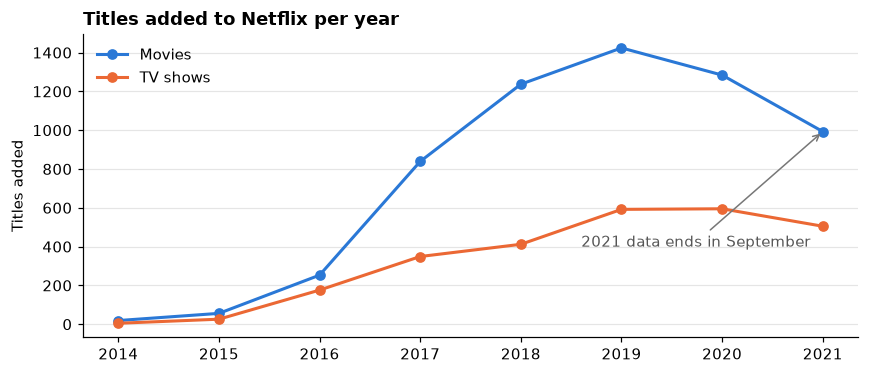

In [12]:
added = (df.dropna(subset=["year_added"])
           .groupby(["year_added", "type"]).size()
           .unstack(fill_value=0)
           .loc[2014:])

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(added.index, added["Movie"], color=MOVIE_COLOR, linewidth=2, marker="o", label="Movies")
ax.plot(added.index, added["TV Show"], color=TV_COLOR, linewidth=2, marker="o", label="TV shows")
ax.set_title("Titles added to Netflix per year", loc="left", fontweight="bold")
ax.set_ylabel("Titles added")
ax.grid(axis="y")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False)
ax.set_xticks(added.index)
ax.set_xticklabels([str(int(y)) for y in added.index])
ax.annotate("2021 data ends in September", xy=(2021, added.loc[2021, "Movie"]),
            xytext=(2018.6, 400), arrowprops=dict(arrowstyle="->", color="#777"), color="#555")
plt.tight_layout()
plt.show()

Netflix added titles fastest between 2016 and 2019. Movie additions dropped after 2019, while TV show additions stayed fairly steady. The 2021 drop is partly because the dataset stops in September 2021.

### 4.3 Most common genres

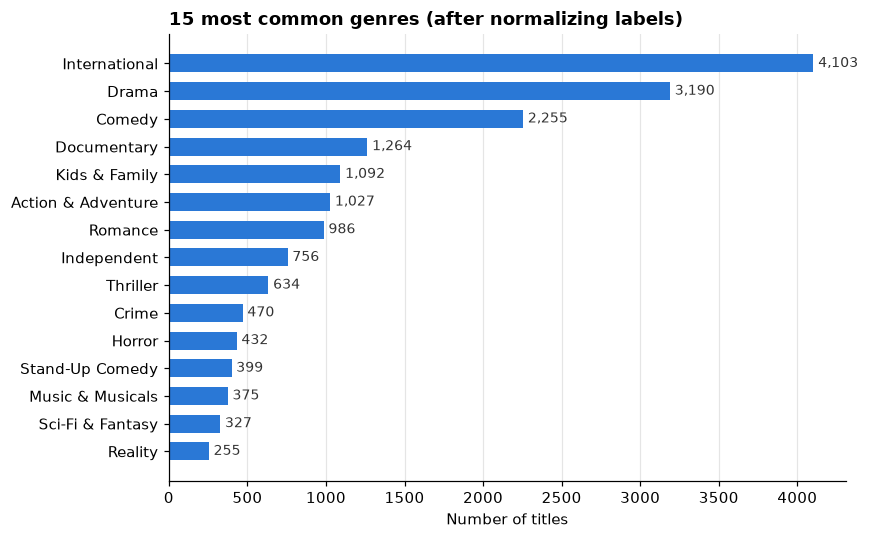

In [13]:
top_genres = pd.Series(base_labels).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top_genres.index, top_genres.values, color=MOVIE_COLOR, height=0.65)
for i, value in enumerate(top_genres.values):
    ax.text(value + 30, i, f"{value:,}", va="center", fontsize=9, color="#333")
ax.set_title("15 most common genres (after normalizing labels)", loc="left", fontweight="bold")
ax.set_xlabel("Number of titles")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

"International" is by far the largest tag, on **4,103 titles (47%)**. It describes where a title comes from rather than what kind of story it is, which becomes important in the pair analysis below.

### 4.4 How many genres does each title have?

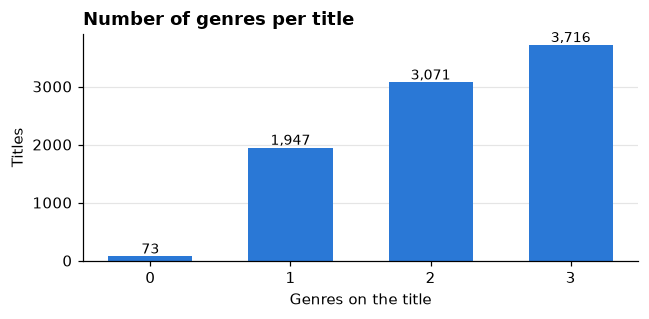

77% of titles have 2 or more genres


In [14]:
genre_count_dist = df["num_genres"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(genre_count_dist.index.astype(str), genre_count_dist.values, color=MOVIE_COLOR, width=0.6)
for x, value in zip(genre_count_dist.index.astype(str), genre_count_dist.values):
    ax.text(x, value + 50, f"{value:,}", ha="center", fontsize=9)
ax.set_title("Number of genres per title", loc="left", fontweight="bold")
ax.set_xlabel("Genres on the title")
ax.set_ylabel("Titles")
ax.grid(axis="y")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

multi = (df["num_genres"] >= 2).mean()
print(f"{multi:.0%} of titles have 2 or more genres")

Most titles have two or three genres, so there are thousands of genre combinations to study. This confirms that genre pairs are a meaningful thing to analyze.

## 5. Genre combination analysis

To count combinations, we look at every pair of genres on each title. A title tagged *Drama, International, Romance* produces three pairs: Drama + International, Drama + Romance, and International + Romance.

### 5.1 Top pairs: with and without "International"

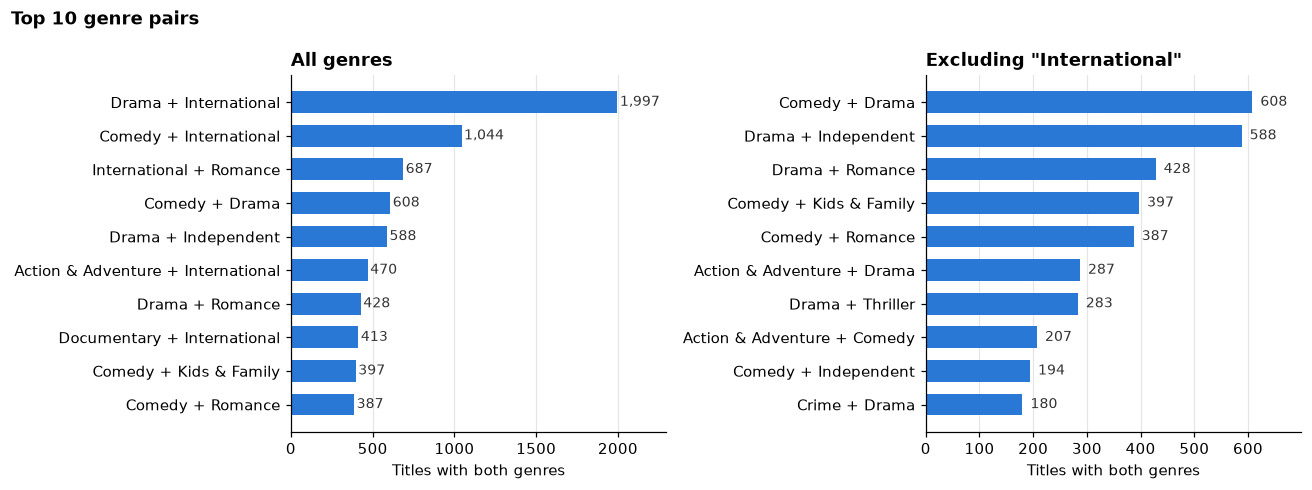

In [15]:
def pairs_to_series(pair_counts, n=10):
    top = pair_counts.most_common(n)
    return pd.Series({f"{a} + {b}": count for (a, b), count in top})

all_pairs = pairs_to_series(count_genre_pairs(df["genres"]))
story_pairs = pairs_to_series(count_genre_pairs(df["genres"], exclude={"International"}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, data, title in [
    (axes[0], all_pairs, "All genres"),
    (axes[1], story_pairs, 'Excluding "International"'),
]:
    ax.barh(data.index, data.values, color=MOVIE_COLOR, height=0.65)
    for i, value in enumerate(data.values):
        ax.text(value + 15, i, f"{value:,}", va="center", fontsize=9, color="#333")
    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_xlabel("Titles with both genres")
    ax.invert_yaxis()
    ax.set_xlim(0, data.max() * 1.15)
fig.suptitle("Top 10 genre pairs", x=0.01, ha="left", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

**With "International" included**, it appears in 5 of the top 10 pairs, which mostly tells us that Netflix has a lot of international content.

**Excluding it** shows the story-based combinations: **Comedy + Drama** is the most common pair (608 titles), followed by **Drama + Independent** and **Drama + Romance**. Because of this, our program will let users choose whether to include "International".

### 5.2 Answering our example question: Romance + Drama or Romance + Comedy?

In our proposal we asked whether romance is more often paired with drama or with comedy.

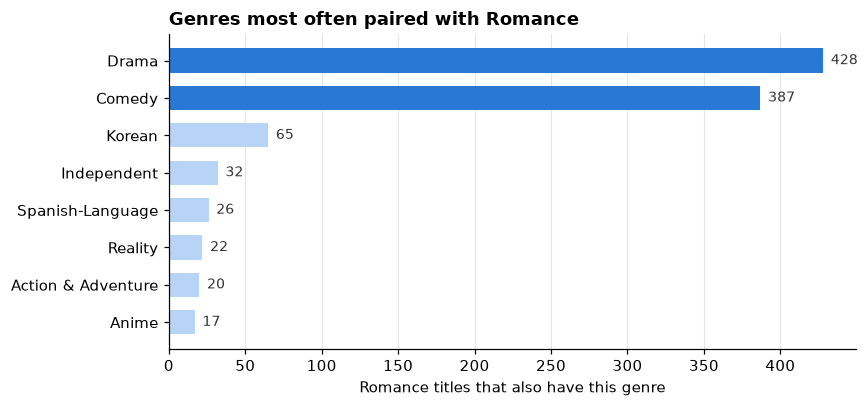

Romance titles: 986
  with Drama:  428 (43%)
  with Comedy: 387 (39%)


In [16]:
romance_partners = pd.Series(
    partner_genres(df["genres"], "Romance", exclude={"International"})
).sort_values(ascending=False).head(8)

fig, ax = plt.subplots(figsize=(8, 3.8))
colors = [MOVIE_COLOR if g in ("Drama", "Comedy") else "#b7d3f6" for g in romance_partners.index]
ax.barh(romance_partners.index, romance_partners.values, color=colors, height=0.65)
for i, value in enumerate(romance_partners.values):
    ax.text(value + 5, i, f"{value:,}", va="center", fontsize=9, color="#333")
ax.set_title("Genres most often paired with Romance", loc="left", fontweight="bold")
ax.set_xlabel("Romance titles that also have this genre")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

total_romance = base_labels["Romance"]
print(f"Romance titles: {total_romance}")
print(f"  with Drama:  {romance_partners['Drama']} ({romance_partners['Drama'] / total_romance:.0%})")
print(f"  with Comedy: {romance_partners['Comedy']} ({romance_partners['Comedy'] / total_romance:.0%})")

Romance is paired with **Drama slightly more often than Comedy** (428 vs. 387 titles), but the two are close. Korean shows stand out as the next most common partner, since Korean TV has many romance series.

### 5.3 Movies vs. TV shows: do the patterns differ?

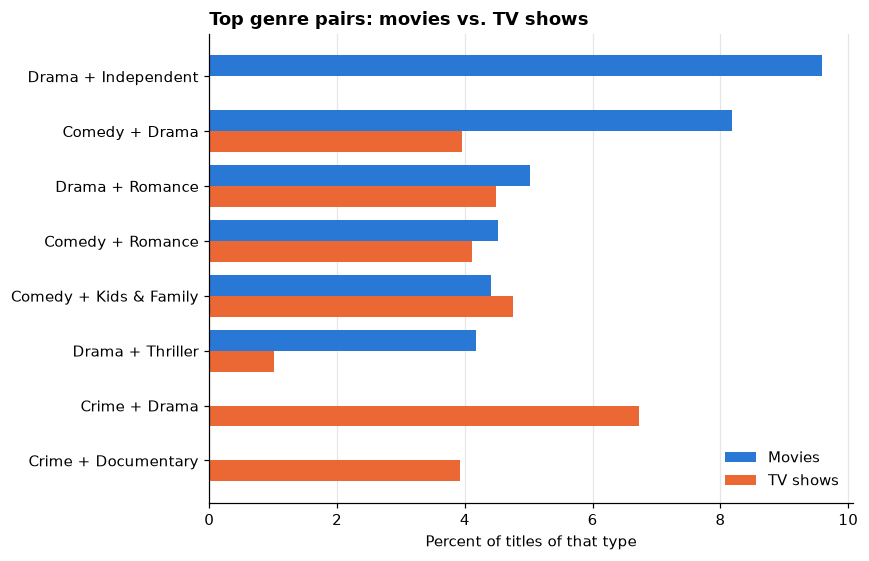

In [17]:
movie_pairs = count_genre_pairs(df.loc[df["type"] == "Movie", "genres"], exclude={"International"})
tv_pairs = count_genre_pairs(df.loc[df["type"] == "TV Show", "genres"], exclude={"International"})
n_movies = (df["type"] == "Movie").sum()
n_tv = (df["type"] == "TV Show").sum()

# Use the top pairs from both types, shown as a share of each type's titles
pair_keys = [p for p, _ in movie_pairs.most_common(6)]
pair_keys += [p for p, _ in tv_pairs.most_common(6) if p not in pair_keys]
labels = [f"{a} + {b}" for a, b in pair_keys]
movie_share = [movie_pairs[p] / n_movies * 100 for p in pair_keys]
tv_share = [tv_pairs[p] / n_tv * 100 for p in pair_keys]

y = np.arange(len(labels))
height = 0.38
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh(y - height / 2, movie_share, height=height, color=MOVIE_COLOR, label="Movies")
ax.barh(y + height / 2, tv_share, height=height, color=TV_COLOR, label="TV shows")
ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.invert_yaxis()
ax.set_xlabel("Percent of titles of that type")
ax.set_title("Top genre pairs: movies vs. TV shows", loc="left", fontweight="bold")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

Comparing **percentages** (not raw counts) makes the comparison fair, since there are more than twice as many movies as shows.

- **Romance** pairs (with Drama or Comedy) appear at similar rates in both.
- **Comedy + Drama** is about twice as common among movies (8%) as among TV shows (4%).
- **Drama + Thriller** is much more common for movies.

**Important limitation we discovered:** some bars are zero because of how Netflix labels titles, not because the combination never happens. Netflix only uses "Crime" for TV shows ("Crime TV Shows") and only uses "Independent" for movies ("Independent Movies"). Crime movies are tagged as Thrillers or Dramas instead. So Crime + Drama looks TV-only, and Drama + Independent looks movie-only. We will point this out to users in the final program.

### 5.4 Genre co-occurrence heatmap

This heatmap shows every pair among the 12 most common story genres at once. Darker cells mean the two genres appear together more often.

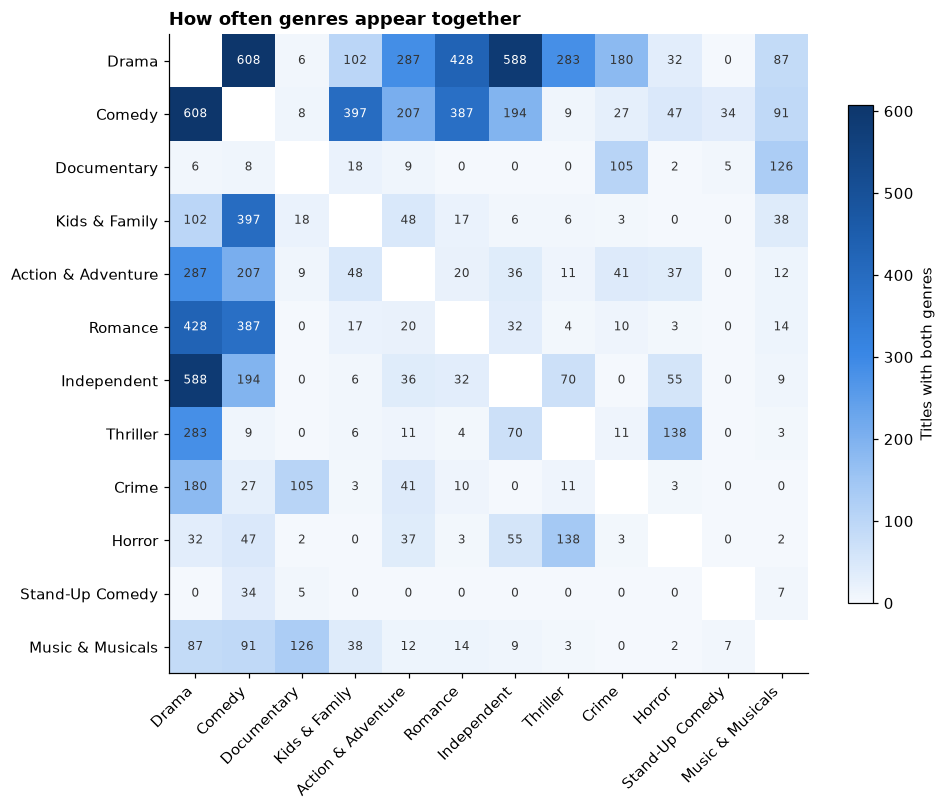

In [18]:
from matplotlib.colors import LinearSegmentedColormap

story_genres = [g for g, _ in count_genres(df["genres"]).most_common(20)
                if g not in ("International", "British", "Spanish-Language", "Korean")][:12]
matrix = co_occurrence_matrix(df["genres"], story_genres)

blues = LinearSegmentedColormap.from_list(
    "blues", ["#f4f8fd", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])
masked = matrix.where(~np.eye(len(story_genres), dtype=bool))  # blank the diagonal

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(masked, cmap=blues)
ax.set_xticks(range(len(story_genres)))
ax.set_yticks(range(len(story_genres)))
ax.set_xticklabels(story_genres, rotation=45, ha="right")
ax.set_yticklabels(story_genres)
ax.grid(False)
for i in range(len(story_genres)):
    for j in range(len(story_genres)):
        if i != j:
            value = matrix.iloc[i, j]
            ax.text(j, i, value, ha="center", va="center", fontsize=8,
                    color="white" if value > 300 else "#333")
fig.colorbar(im, ax=ax, shrink=0.75, label="Titles with both genres")
ax.set_title("How often genres appear together", loc="left", fontweight="bold")
plt.tight_layout()
plt.show()

Drama is the connecting genre: it pairs strongly with Comedy, Independent, Romance, Thriller, Action & Adventure, and Crime. Some genres are almost never combined, such as Documentary with Romance or Horror with Kids & Family, which also makes sense.

## 6. Recommender prototype

A first version of the recommendation feature. Each title gets a **match score** equal to how many of the user's preferred genres it has, and ties are broken by newest release year. The final program will add a user menu around this function.

In [19]:
# Example: a user who wants romantic comedy movies
recommend_titles(df, ["Romance", "Comedy"], content_type="Movie", top_n=8)

,title,type,release_year,rating,listed_in,match_score
0,Afterlife of the Party,Movie,2021,TV-PG,"Comedies, Romantic Movies",2
1,He's All That,Movie,2021,TV-14,"Comedies, Romantic Movies",2
2,The Secret Diary of an Exchange Student,Movie,2021,TV-14,"Comedies, International Movies, Romantic Movies",2
3,The Kissing Booth 3,Movie,2021,TV-14,"Comedies, Romantic Movies",2
4,Slay,Movie,2021,TV-MA,"Comedies, International Movies, Romantic Movies",2
5,Resort to Love,Movie,2021,TV-14,"Comedies, Romantic Movies",2
6,Good on Paper,Movie,2021,TV-MA,"Comedies, Romantic Movies",2
7,Sweet & Sour,Movie,2021,TV-14,"Comedies, International Movies, Romantic Movies",2


In [20]:
# Example: a user who wants crime dramas, TV shows only
recommend_titles(df, ["Crime", "Drama", "Thriller"], content_type="TV Show", top_n=8)

,title,type,release_year,rating,listed_in,match_score
0,Ozark,TV Show,2020,TV-MA,"Crime TV Shows, TV Dramas, TV Thrillers",3
1,Dare Me,TV Show,2019,TV-MA,"Crime TV Shows, TV Dramas, TV Thrillers",3
2,The Blacklist,TV Show,2019,TV-14,"Crime TV Shows, TV Dramas, TV Thrillers",3
3,Designated Survivor,TV Show,2019,TV-MA,"Crime TV Shows, TV Dramas, TV Thrillers",3
4,The Assassination of Gianni Versace,TV Show,2018,TV-MA,"Crime TV Shows, TV Dramas, TV Thrillers",3
5,The Lizzie Borden Chronicles,TV Show,2015,TV-14,"Crime TV Shows, TV Dramas, TV Thrillers",3
6,Breaking Bad,TV Show,2013,TV-MA,"Crime TV Shows, TV Dramas, TV Thrillers",3
7,Squid Game,TV Show,2021,TV-MA,"International TV Shows, TV Dramas, TV Thrillers",2


## 7. Summary of findings so far

1. **Data quality:** The genre column is complete. We fixed 3 misplaced runtimes in `rating`, filled missing text fields, and converted dates and durations into usable types.
2. **Label normalization was necessary:** 42 raw labels became 26 base genres, which allows fair movie vs. TV comparisons.
3. **"International" dominates** the raw pair counts (47% of titles), so we analyze pairs with and without it.
4. **Comedy + Drama** is the most common story pair overall. Some genres ("Crime", "Independent") only exist for one content type, which limits movie vs. TV comparisons for those genres.
5. **Romance** is paired with Drama slightly more than with Comedy (428 vs. 387).
6. A working **recommender prototype** already returns sensible results.

**Next steps:** build the interactive program (user menu for exploring pairs and getting recommendations), improve the recommender (filters for rating and release year), and add tests for the cleaning functions.